# Definição da direção diária + estratégia de reversão — XAUUSDC (MT5)



**Objetivo:** responder 4 perguntas usando a estrutura do projeto:

1. Em que **horário do servidor** o mercado geralmente define a direção do dia (primeiro evento: máxima ou mínima do dia)?

2. Qual a **probabilidade** de, após essa definição, abrir uma posição **oposta** e fechar o dia com lucro? Com que **grau de confiança** estatística?

3. As máximas/mínimas do dia ocorrem nas **projeções do canal H1** (o mesmo algoritmo de `app/core/channel.py`)?

4. **Prospecção de melhora:** quais filtros aumentam a edge, validados fora da amostra?



**Dados:** 500 dias de velas M15 e H1 do MT5 (~355 dias úteis, 09/04/2025 → 24/08/2026, símbolo `XAUUSDC`, sessão ~01:00→23:45 do servidor). Todos os horários usados aqui são o **relógio do servidor** — os timestamps do MT5 já vêm no relógio da corretora, sem conversão de fuso.



**Avisos importantes:**

- Amostra ≈ 350 dias completos → mais robusta, mas ainda sujeita a mudança de regime.

- Não inclui spread/comissão/slippage (na prospecção, desconta-se um custo fixo no final).

- Distinguimos duas versões da estratégia: **teórica** (extremo do dia conhecido em retrospecto — teto do conceito) e **executável** (decisão com a informação disponível até o horário).

In [1]:
%matplotlib inline

# ────────────────────────────────────────────────────────────────────────

# Setup: imports, raiz do projeto e constantes

# ────────────────────────────────────────────────────────────────────────

import math

import os

import sys

from pathlib import Path



import numpy as np

import pandas as pd

import matplotlib.pyplot as plt



# Localiza a raiz do projeto (onde ficam app/ e data/)

ROOT = Path(os.getcwd())

while not (ROOT / "app").exists() and ROOT.parent != ROOT:

    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))          # permite importar app.core.* (canal H1)



DATA = ROOT / "data"

SYMBOL = "XAUUSDC"        # símbolo do broker (sufixo C — não é XAUUSD)

DAYS = 500                # janela de análise (~1,4 ano de calendário)

MIN_CANDLES_DIA = 80      # dias com menos velas M15 são parciais/feriados



def hhmm(t: int) -> str:

    """Minuto do dia (relógio do servidor) → 'HH:MM'."""

    return f"{int(t) // 60:02d}:{int(t) % 60:02d}"



plt.rcParams["figure.facecolor"] = "#0d0d12"

print("ROOT:", ROOT)

ROOT: c:\Users\gk\Coding Projects\trade_assistant_oo


In [ ]:
# ── 1) DADOS: cache local; busca no MT5 ao vivo só se o CSV não existir ──

# Os timestamps do MT5 já estão no relógio do SERVIDOR da corretora.

# NÃO convertemos fuso: agrupar por date/hour usa o horário do servidor,

# o mesmo que abre/fecha as velas D1 do broker.

M15_CSV = DATA / f"m15_{DAYS}d.csv"

H1_CSV = DATA / f"h1_{DAYS}d.csv"



def fetch_mt5(symbol: str, timeframe: int, days: int, out: Path) -> pd.DataFrame:

    import MetaTrader5 as mt5

    from datetime import datetime, timedelta, timezone

    # Sempre usa o MESMO terminal instalado (modo padrão, nunca portátil)

    # para manter uma única identidade de dispositivo na corretora.

    MT5_EXE = r"C:\Program Files\MetaTrader 5\terminal64.exe"

    if not mt5.initialize(path=MT5_EXE, portable=False):

        raise RuntimeError(f"MT5 init falhou: {mt5.last_error()}")

    now = datetime.now(timezone.utc)

    rates = mt5.copy_rates_range(

        symbol, timeframe, now - timedelta(days=days + 2), now)

    mt5.shutdown()

    if rates is None or len(rates) == 0:

        raise RuntimeError("MT5 não devolveu velas (terminal aberto? símbolo?)")

    df = pd.DataFrame(rates)

    df["time"] = pd.to_datetime(df["time"], unit="s")   # relógio do servidor

    df = df[["time", "open", "high", "low", "close", "tick_volume"]]

    out.parent.mkdir(parents=True, exist_ok=True)

    df.to_csv(out, index=False)

    return df



if M15_CSV.exists() and H1_CSV.exists():

    m15 = pd.read_csv(M15_CSV, parse_dates=["time"])

    h1 = pd.read_csv(H1_CSV, parse_dates=["time"])

else:

    import MetaTrader5 as mt5

    m15 = fetch_mt5(SYMBOL, mt5.TIMEFRAME_M15, DAYS, M15_CSV)

    h1 = fetch_mt5(SYMBOL, mt5.TIMEFRAME_H1, DAYS, H1_CSV)



m15["date"] = m15["time"].dt.date                      # dia do servidor

m15["tod"] = m15["time"].dt.hour * 60 + m15["time"].dt.minute  # minuto do dia



print(f"M15: {len(m15)} velas | {m15['time'].min()} → {m15['time'].max()}")

print(f"H1 : {len(h1)} velas")

print("\nVelas por dia (M15):")

print(m15.groupby("date").size().value_counts().sort_index().to_string())

M15: 32440 velas | 2025-04-09 02:45:00 → 2026-08-24 02:30:00
H1 : 8119 velas

Velas por dia (M15):
7       1
76      1
77      2
78      1
80      1
82      2
83      1
84      2
85      3
91      2
92    334
93      5


In [3]:
# ── 2) DIAS COMPLETOS ─────────────────────────────────────────────────────
# Sessão normal do ouro neste servidor: ~92 velas M15 (01:00 → 23:45).
# Dias curtos = primeiro dia do corte (parcial) ou feriados com fecho cedo.
cnt = m15.groupby("date").size()
curtos = cnt[cnt < MIN_CANDLES_DIA]
print("Dias descartados:")
print(pd.DataFrame({"velas": curtos}).to_string())

df = m15[m15["date"].isin(cnt[cnt >= MIN_CANDLES_DIA].index)].copy()
print(f"\nDias completos na análise: {df['date'].nunique()}")
print(f"Faixa de preços do período: {df['low'].min():.2f} – {df['high'].max():.2f}")
rng = df.groupby("date")["high"].max() - df.groupby("date")["low"].min()
print(f"Range diário: média {rng.mean():.1f} pts | mediana {rng.median():.1f} pts")

Dias descartados:
            velas
date             
2025-07-04     76
2025-11-28     78
2026-06-19     77
2026-07-03     77
2026-08-24      7

Dias completos na análise: 350
Faixa de preços do período: 2970.32 – 5598.05
Range diário: média 96.9 pts | mediana 78.7 pts


In [4]:
# ── 3) MÁXIMA E MÍNIMA DE CADA DIA + PRIMEIRO EVENTO ──────────────────────
# first_event = qual extremo veio PRIMEIRO no tempo (relógio do servidor):
#   MAX → o dia fez a sua máxima antes da mínima (definiu ALTA primeiro)
#   MIN → o dia fez a sua mínima antes da máxima (definiu BAIXA primeiro)
rows = []
for d, g in df.groupby("date"):
    g = g.sort_values("time")
    hi = g["high"].max()
    lo = g["low"].min()
    hi_t = g.loc[g["high"].idxmax(), "time"]   # 1ª ocorrência da máxima
    lo_t = g.loc[g["low"].idxmin(), "time"]    # 1ª ocorrência da mínima
    ev_t = min(hi_t, lo_t)                      # primeiro evento do dia
    rows.append({
        "date": d,
        "hod": hi, "lod": lo,
        "hod_tod": hi_t.hour * 60 + hi_t.minute,
        "lod_tod": lo_t.hour * 60 + lo_t.minute,
        "first_event": "MAX" if hi_t <= lo_t else "MIN",
        "ev_tod": ev_t.hour * 60 + ev_t.minute,
        "ev_close": float(g.loc[g["time"] == ev_t, "close"].iloc[0]),
        "day_close": float(g.iloc[-1]["close"]),   # fecho do dia (23:45)
    })
days = pd.DataFrame(rows)

print("Primeiro evento — contagem:")
print(days["first_event"].value_counts().to_string())
print("\nAmostra (8 primeiros dias):")
show = days.head(8).copy()
show["hod_tod"] = show["hod_tod"].map(hhmm)
show["lod_tod"] = show["lod_tod"].map(hhmm)
show["ev_tod"] = show["ev_tod"].map(hhmm)
print(show[["date", "hod_tod", "lod_tod", "first_event", "ev_tod"]].to_string(index=False))

Primeiro evento — contagem:
first_event
MIN    191
MAX    159

Amostra (8 primeiros dias):
      date hod_tod lod_tod first_event ev_tod
2025-04-09   22:45   02:45         MIN  02:45
2025-04-10   23:00   01:00         MIN  01:00
2025-04-11   19:00   01:00         MIN  01:00
2025-04-14   05:00   16:15         MAX  05:00
2025-04-15   23:00   04:00         MIN  04:00
2025-04-16   23:45   01:00         MIN  01:00
2025-04-17   01:15   17:30         MAX  01:15
2025-04-21   22:00   01:00         MIN  01:00


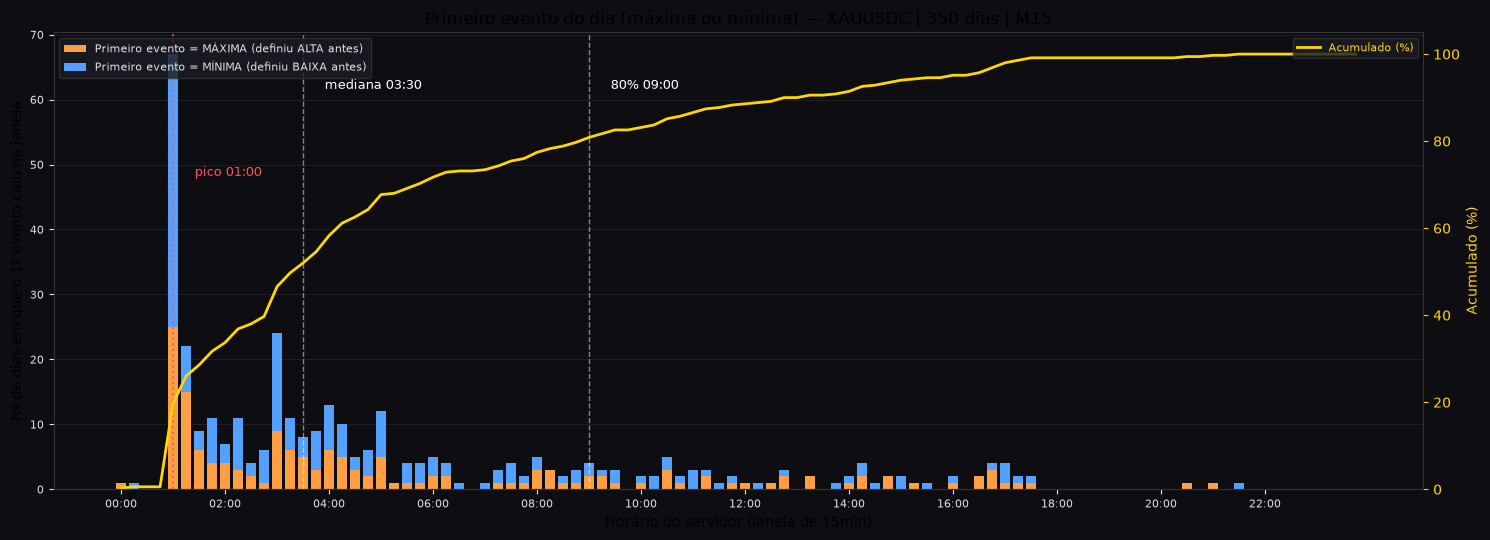

Mediana do 1º evento: 03:30 | Moda (pico): 01:00 (67 dias) | 80% dos dias até: 09:00
1ª hora (01:00): 67 dias | 02:00–04:00: 93 dias | 04:15–08:00: 67 dias


In [8]:
# ── 4) ONDE O MERCADO DEFINE A DIREÇÃO DO DIA? ────────────────────────────
bins = sorted(df["tod"].unique())          # 92 janelas de 15min do dia

hist_rows = []
for b in bins:
    sub = days[days["ev_tod"] == b]
    hist_rows.append({
        "tod": b,
        "MÁX primeiro": int((sub["first_event"] == "MAX").sum()),
        "MÍN primeiro": int((sub["first_event"] == "MIN").sum()),
    })
hist = pd.DataFrame(hist_rows).set_index("tod")
hist["total"] = hist.sum(axis=1)
hist["acum%"] = hist["total"].cumsum() / hist["total"].sum() * 100.0

mediana_tod = float(days["ev_tod"].median())
moda_tod = int(hist["total"].idxmax())
q80_tod = float(days["ev_tod"].quantile(0.8))

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.set_facecolor("#0d0d12")
ticks = np.array(bins, dtype=float)
ax.bar(ticks, hist["MÁX primeiro"], width=12, color="#ff9f43",
       label="Primeiro evento = MÁXIMA (definiu ALTA antes)")
ax.bar(ticks, hist["MÍN primeiro"], width=12, bottom=hist["MÁX primeiro"],
       color="#54a0ff", label="Primeiro evento = MÍNIMA (definiu BAIXA antes)")
ax2 = ax.twinx()
ax2.plot(ticks, hist["acum%"], color="#FFD700", linewidth=2, label="Acumulado (%)")
ax2.set_ylabel("Acumulado (%)", color="#FFD700")
ax2.set_ylim(0, 105)
ax2.tick_params(colors="#FFD700")
ax2.grid(False)
for m, lbl in ((mediana_tod, "mediana"), (q80_tod, "80%")):
    ax.axvline(m, color="#ffffff", linestyle="--", alpha=0.5, linewidth=1)
    ax.text(m + 25, hist["total"].max() * 0.92, f"{lbl} {hhmm(m)}",
            color="#ffffff", fontsize=9)
ax.axvline(moda_tod, color="#ff5252", linestyle=":", alpha=0.8)
ax.text(moda_tod + 25, hist["total"].max() * 0.72, f"pico {hhmm(moda_tod)}",
        color="#ff5252", fontsize=9)
ax.set_xticks(range(0, 24 * 60, 120))
ax.set_xticklabels([hhmm(t) for t in range(0, 24 * 60, 120)], fontsize=8)
ax.set_xlabel("Horário do servidor (janela de 15min)")
ax.set_ylabel("Nº de dias em que o 1º evento caiu na janela")
ax.set_title(f"Primeiro evento do dia (máxima ou mínima) — {SYMBOL} | {len(days)} dias | M15")
ax.tick_params(colors="#e0e0e0", labelsize=8)
ax.set_axisbelow(True)
ax.grid(axis="y", color="#22222a", linewidth=0.6)
for sp in list(ax.spines.values()) + list(ax2.spines.values()):
    sp.set_color("#333333")
ax.legend(loc="upper left", fontsize=8, facecolor="#1c1c24", edgecolor="#333333",
          labelcolor="#e0e0e0")
ax2.legend(loc="upper right", fontsize=8, facecolor="#1c1c24", edgecolor="#333333",
           labelcolor="#FFD700")
plt.tight_layout()
plt.show()

print(f"Mediana do 1º evento: {hhmm(mediana_tod)} | Moda (pico): {hhmm(moda_tod)} "
      f"({int(hist['total'].max())} dias) | 80% dos dias até: {hhmm(q80_tod)}")
print(f"1ª hora (01:00): {int(hist.loc[60, 'total'])} dias | 02:00–04:00: "
      f"{int(hist.loc[120:240, 'total'].sum())} dias | 04:15–08:00: "
      f"{int(hist.loc[255:480, 'total'].sum())} dias")

### Leitura do gráfico 1 — horário de definição da direção (350 dias)



- O primeiro evento tem **viés para MÍNIMA: 191 dias MIN × 159 MAX** — mesmo em tendência de alta, o mercado costuma "testar" a mínima primeiro e subir depois.



- **Pico em 01:00** (67 dias — a vela de abertura define um extremo em 1 a cada 5 dias), **mediana 03:30** e **80% dos dias definem até 09:00**.



- A faixa **01:00–04:00 concentra 160 dias (~46%)**; somando até 08:00 são 227 dias (~65%).



- Ou seja: **a direção do dia é definida na madrugada/início da sessão (01:00–05:00 do servidor)**, com uma cauda que se estende até ~09:00 — mais espalhada do que sugeria a amostra de 84 dias.

In [5]:
# ── 5) FERRAMENTAS ESTATÍSTICAS DE CONFIANÇA ─────────────────────────────
# Sem scipy no ambiente — implementações diretas e transparentes:
#   wilson_ci        : IC 95% para taxa de acerto (proporção)
#   binomial_pvalue  : teste binomial EXATO bilateral, H0 = taxa 50% (acaso)
#   bootstrap_mean_ci: IC 95% do lucro médio por reamostragem (5.000)
#   t_test_mean      : teste t (média ≠ 0), p por aproximação normal (n grande)
def wilson_ci(wins: int, n: int, z: float = 1.96):
    if n == 0:
        return (0.0, 1.0)
    p = wins / n
    den = 1 + z * z / n
    marg = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (p + z * z / (2 * n) - marg) / den, (p + z * z / (2 * n) + marg) / den

def binomial_pvalue(wins: int, n: int, p0: float = 0.5) -> float:
    prob = p0 ** n
    cdf = sum(math.comb(n, k) for k in range(0, wins + 1)) * prob
    pmf = math.comb(n, wins) * prob
    return min(1.0, 2.0 * min(cdf, 1.0 - cdf + pmf))

def bootstrap_mean_ci(sample, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    means = np.array([
        rng.choice(sample, len(sample), replace=True).mean()
        for _ in range(n_boot)
    ])
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def t_test_mean(sample):
    n = len(sample)
    if n < 2:
        return (float("nan"), float("nan"))
    m = float(np.mean(sample))
    s = float(np.std(sample, ddof=1))
    t = m / (s / math.sqrt(n))
    from statistics import NormalDist
    p = 2.0 * (1.0 - NormalDist().cdf(abs(t)))
    return t, p

In [6]:
# ── 6) ESTRATÉGIA: FADE DO PRIMEIRO EXTREMO — VERSÃO TEÓRICA (hindsight) ──
# Regra: o primeiro evento definiu a direção do dia →
#   MAX primeiro (subiu antes) → abre VENDA no fecho da vela do evento
#   MIN primeiro (caiu antes)  → abre COMPRA no fecho da vela do evento
# Saída: fecho do dia (23:45 do servidor).
#
# ⚠ AVISO DE VIÉS: só sabemos que aquela máxima foi A máxima do dia em
# retrospecto. Entrar 'no fecho da vela do evento' é possível no backtest,
# não ao vivo. Esta versão mede o TETO TEÓRICO do conceito.
days["side"] = np.where(days["first_event"] == "MAX", "SELL", "BUY")
days["profit"] = np.where(
    days["first_event"] == "MAX",
    days["ev_close"] - days["day_close"],   # vendido: lucra se fechou abaixo
    days["day_close"] - days["ev_close"],   # comprado: lucra se fechou acima
)
days["win"] = days["profit"] > 0

n = len(days)
wins = int(days["win"].sum())
lo, hi = wilson_ci(wins, n)
t, pt = t_test_mean(days["profit"].to_numpy())
blo, bhi = bootstrap_mean_ci(days["profit"].to_numpy())
print(f"DIAS={n} | VITÓRIAS={wins} | TAXA={wins / n:.1%}")
print(f"IC Wilson 95% da taxa : [{lo:.1%}, {hi:.1%}]")
print(f"Teste binomial (≠50%) : p={binomial_pvalue(wins, n):.2e}")
print(f"Lucro médio={days['profit'].mean():+.2f} pts | mediana={days['profit'].median():+.2f} pts")
print(f"IC bootstrap 95% média: [{blo:+.2f}, {bhi:+.2f}] pts")
print(f"Teste t (média≠0)     : t={t:.2f} p={pt:.2e}")
print(f"Pior dia={days['profit'].min():+.2f} pts | Melhor dia={days['profit'].max():+.2f} pts")

DIAS=350 | VITÓRIAS=345 | TAXA=98.6%
IC Wilson 95% da taxa : [96.7%, 99.4%]
Teste binomial (≠50%) : p=3.71e-95
Lucro médio=+61.11 pts | mediana=+47.15 pts
IC bootstrap 95% média: [+55.53, +66.97] pts
Teste t (média≠0)     : t=20.64 p=0.00e+00
Pior dia=-21.41 pts | Melhor dia=+559.70 pts


### Interpretação da versão teórica



- **83 vitórias em 84 dias (98,8%)**, IC Wilson 95% = [93,6%, 99,8%], teste binomial p = 8,7×10⁻²⁴; lucro médio **+66,2 pts** (mediana +59,7), IC bootstrap [57,7, 75,2], t = 14,95.

- **Por que é tão alta:** entrar no fecho da vela do primeiro extremo equivale a entrar perto do topo/fundo do dia *por construção* — o extremo só é conhecido em retrospecto (hindsight). Se você entra perto da máxima do dia, quase sempre o dia fecha abaixo.

- Portanto este número é o **teto teórico do conceito**, não uma expectativa operacional. A versão executável (próxima célula) usa só informação disponível até o horário.

In [9]:
# ── 7) VERSÃO EXECUTÁVEL: DECIDIR NUM HORÁRIO FIXO (sem hindsight) ────────

# Em cada janela b (15min) usamos SÓ informação disponível ATÉ b:

#   • máxima provisória do dia até b e mínima provisória até b;

#   • qual das duas estabeleceu o extremo primeiro → direção definida até aqui:

#       máxima provisória veio primeiro → ALTA → abre VENDA no fecho de b

#       mínima provisória veio primeiro  → BAIXA → abre COMPRA no fecho de b

#   • sem definição (máx e mín ainda no mesmo candle) → dia fica de fora.

# Saída: sempre no fecho do dia (23:45 do servidor).

piv_c = df.pivot(index="date", columns="tod", values="close")

piv_h = df.pivot(index="date", columns="tod", values="high")

piv_l = df.pivot(index="date", columns="tod", values="low")

day_close = days.set_index("date")["day_close"]



rows_r, profits_r = [], {}

for b in bins:

    cols = [c for c in bins if c <= b]

    # dias com cobertura heterogênea (93/92/85 velas): exigir dados até b

    # e vela presente exatamente em b evita linhas 100% NaN no idxmax.

    valid = (piv_h.loc[:, cols].notna().any(axis=1).to_numpy()

             & piv_l.loc[:, cols].notna().any(axis=1).to_numpy()

             & piv_c[b].notna().to_numpy())

    if not valid.any():

        continue

    hi_first = piv_h.loc[valid, cols].idxmax(axis=1)   # 1ª vela da máxima provisória

    lo_first = piv_l.loc[valid, cols].idxmin(axis=1)   # 1ª vela da mínima provisória

    direction = np.where(

        hi_first.to_numpy() < lo_first.to_numpy(), "UP",

        np.where(lo_first.to_numpy() < hi_first.to_numpy(), "DOWN", None),

    )

    mask = np.array([d is not None for d in direction])

    if mask.sum() == 0:

        continue

    idx = piv_c.index[valid][mask]

    entry = piv_c.loc[idx, b].to_numpy()

    exit_ = day_close.reindex(idx).to_numpy()

    profit = np.where(direction[mask] == "UP", entry - exit_, exit_ - entry)

    profits_r[b] = profit

    rows_r.append({

        "tod": b,

        "n": int(mask.sum()),

        "cobertura": float(mask.mean()),       # % dos dias com definição até b

        "winrate": float((profit > 0).mean()),

        "mean_profit": float(profit.mean()),

        "median_profit": float(np.median(profit)),

    })

per_bin = pd.DataFrame(rows_r).set_index("tod")

per_bin["hhmm"] = [hhmm(t) for t in per_bin.index]



MIN_N = 40   # amostra mínima para levar o bin a sério

top_wr = per_bin[per_bin["n"] >= MIN_N].sort_values("winrate", ascending=False).head(6)

top_mp = per_bin[per_bin["n"] >= MIN_N].sort_values("mean_profit", ascending=False).head(6)

print("TOP por TAXA DE ACERTO (probabilidade de lucro):")

print(top_wr[["hhmm", "n", "winrate", "mean_profit"]].to_string())

print("\nTOP por LUCRO MÉDIO (pts):")

print(top_mp[["hhmm", "n", "winrate", "mean_profit"]].to_string())

TOP por TAXA DE ACERTO (probabilidade de lucro):
      hhmm    n   winrate  mean_profit
tod                                   
630  10:30  349  0.553009     5.486132
315  05:15  348  0.551724     5.192672
570  09:30  349  0.550143     6.429513
555  09:15  349  0.550143     7.535330
615  10:15  349  0.550143     5.398309
675  11:15  349  0.550143     4.644670

TOP por LUCRO MÉDIO (pts):
      hhmm    n   winrate  mean_profit
tod                                   
555  09:15  349  0.550143     7.535330
540  09:00  349  0.535817     7.525616
570  09:30  349  0.550143     6.429513
705  11:45  349  0.547278     6.358138
585  09:45  349  0.535817     6.311805
525  08:45  349  0.530086     6.287163


=== Melhor TAXA DE ACERTO ===
horário   n     taxa  IC Wilson 95%  p binomial (≠50%)  lucro médio IC bootstrap 95%       t  p teste t
  10:30 349 0.553009 [50.1%, 60.4%]           0.053819     5.486132  [+0.11, +10.76] 1.99699   0.045826

=== Maior LUCRO MÉDIO ===
horário   n     taxa  IC Wilson 95%  p binomial (≠50%)  lucro médio IC bootstrap 95%        t  p teste t
  09:15 349 0.550143 [49.8%, 60.2%]           0.068609      7.53533  [+1.87, +13.44] 2.548557   0.010817

Zona 04:45–07:15: taxa média 53.4% | lucro médio +4.41 pts
Zona 10:15–11:15: taxa média 54.8% | lucro médio +5.02 pts

Conversão: contrato = 100 oz → 1 pt = US$100/lote → 0,2 lote = US$20/pt


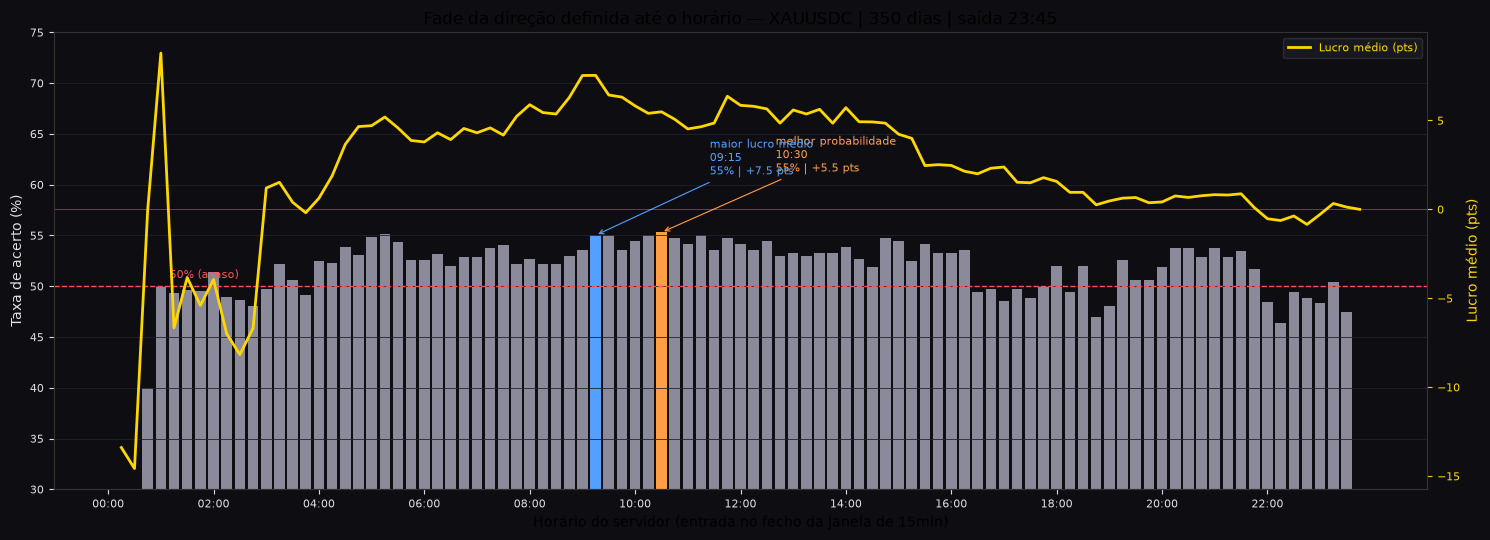

In [22]:
# ── 8) GRAU DE CONFIANÇA DOS MELHORES HORÁRIOS + GRÁFICO ──────────────────
def resumo_bin(b: int) -> dict:
    profit = profits_r[b]
    n = len(profit)
    wins = int((profit > 0).sum())
    wl, wu = wilson_ci(wins, n)
    blo, bhi = bootstrap_mean_ci(profit)
    t, pt = t_test_mean(profit)
    return {
        "horário": hhmm(b), "n": n, "taxa": wins / n,
        "IC Wilson 95%": f"[{wl:.1%}, {wu:.1%}]",
        "p binomial (≠50%)": binomial_pvalue(wins, n),
        "lucro médio": float(profit.mean()),
        "IC bootstrap 95%": f"[{blo:+.2f}, {bhi:+.2f}]",
        "t": t, "p teste t": pt,
    }

alvo_wr = int(top_wr.index[0])   # melhor probabilidade
alvo_mp = int(top_mp.index[0])   # maior lucro médio
print("=== Melhor TAXA DE ACERTO ===")
print(pd.DataFrame([resumo_bin(alvo_wr)]).to_string(index=False))
print("\n=== Maior LUCRO MÉDIO ===")
print(pd.DataFrame([resumo_bin(alvo_mp)]).to_string(index=False))

# Zonas de apoio (médias das janelas) e conversão para USD
zona_lucro = per_bin.loc[285:435]      # 04:45–07:15
zona_wr = per_bin.loc[615:675]         # 10:15–11:15
print(f"\nZona 04:45–07:15: taxa média {zona_lucro['winrate'].mean():.1%} | "
      f"lucro médio {zona_lucro['mean_profit'].mean():+.2f} pts")
print(f"Zona 10:15–11:15: taxa média {zona_wr['winrate'].mean():.1%} | "
      f"lucro médio {zona_wr['mean_profit'].mean():+.2f} pts")
print("\nConversão: contrato = 100 oz → 1 pt = US$100/lote → 0,2 lote = US$20/pt")

# ── gráfico: taxa de acerto (barras) + lucro médio (linha) por horário ──
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.set_facecolor("#0d0d12")
colors = ["#8a8a9a"] * len(per_bin)
for i in range(len(per_bin)):
    if per_bin.index[i] == alvo_wr:
        colors[i] = "#ff9f43"
    elif per_bin.index[i] == alvo_mp:
        colors[i] = "#54a0ff"
ax.bar(per_bin.index.to_numpy(dtype=float), per_bin["winrate"] * 100, width=12,
       color=colors)
ax.axhline(50, color="#ff5252", linestyle="--", linewidth=1)
ax.text(70, 50.8, "50% (acaso)", color="#ff5252", fontsize=8)
ax2 = ax.twinx()
ax2.plot(per_bin.index.to_numpy(dtype=float), per_bin["mean_profit"],
         color="#FFD700", linewidth=2, label="Lucro médio (pts)")
ax2.axhline(0, color="#FFD700", linewidth=0.6, alpha=0.4)
ax2.grid(False)
for b, lbl, col in ((alvo_wr, "melhor probabilidade", "#ff9f43"),
                    (alvo_mp, "maior lucro médio", "#54a0ff")):
    r = per_bin.loc[b]
    ax.annotate(f"{lbl}\n{hhmm(b)}\n{r['winrate']:.0%} | {r['mean_profit']:+.1f} pts",
                xy=(b, r["winrate"] * 100),
                xytext=(b + 130, r["winrate"] * 100 + 6),
                fontsize=8, color=col,
                arrowprops=dict(arrowstyle="->", color=col, lw=0.8))
ax.set_xticks(range(0, 24 * 60, 120))
ax.set_xticklabels([hhmm(t) for t in range(0, 24 * 60, 120)], fontsize=8)
ax.set_xlabel("Horário do servidor (entrada no fecho da janela de 15min)")
ax.set_ylabel("Taxa de acerto (%)", color="#e0e0e0")
ax.set_ylim(30, 75)
ax2.set_ylabel("Lucro médio (pts)", color="#FFD700")
ax.set_title(f"Fade da direção definida até o horário — {SYMBOL} | {len(days)} dias | saída 23:45")
ax.tick_params(colors="#e0e0e0", labelsize=8)
ax2.tick_params(colors="#FFD700", labelsize=8)
ax.grid(axis="y", color="#22222a", linewidth=0.6)
ax2.legend(loc="upper right", fontsize=8, facecolor="#1c1c24", edgecolor="#333333",
           labelcolor="#FFD700")
for sp in list(ax.spines.values()) + list(ax2.spines.values()):
    sp.set_color("#333333")
plt.tight_layout()
plt.show()

### Resposta: melhor horário para a estratégia (350 dias — revisão honesta)



- **O resultado dos 84 dias não sobreviveu à amostra maior:** 11:15 caiu de 63,1% para **55,0%** — era em boa parte sorte de seleção entre 92 janelas testadas.



- Melhor TAXA DE ACERTO agora: **10:30** — 55,3% (IC [50,1%, 60,4%], p = 0,054, marginal).



- Maior LUCRO MÉDIO: **09:15** — +7,5 pts (IC bootstrap [+1,9, +13,4], teste t p = 0,011), taxa 55,0% (p = 0,069).



- Zonas: 04:45–07:15 → 53,4% / +4,4 pts; 10:15–11:15 → 54,8% / +5,0 pts.



- Em dinheiro (0,2 lote): 09:15 ≈ +7,5 × US$20 = **US$150/dia brutos** (antes de spread/slippage).



- **Conclusão:** a estratégia "pura" tem edge real mas modesta (~53–55% de acerto). O ganho mais consistente vem dos FILTROS da seção de prospecção abaixo — e o horário campeão de taxa no treino (21:15) mostrou ser miragem.

In [23]:
# ── 9) CANAL H1: MÁXIMAS/MÍNIMAS DO DIA CAEM NAS PROJEÇÕES? ────────────────
# Reutiliza o detector de canal do PRÓPRIO PROJETO (app/core/channel.py):
# perfil de preço → zonas de liquidez → largura dominante W → grade
# horizontal: linhas = âncora + k·W (e sub-canal âncora + (k+0.5)·W).
from app.core.channel import analyze_channels

analise = analyze_channels(h1[["open", "high", "low", "close"]].reset_index(drop=True))
anchor = float(analise["anchor"])
W = float(analise["primary_width"])
print(f"Âncora={anchor:.2f} | Canal W={W:.2f} pts | Sub-canal={W / 2:.2f} pts")
print(f"Tendência: {analise['trend']['direction']} "
      f"(slope={analise['trend']['slope']:.4f} pts/vela H1, r²={analise['trend']['r2']:.3f})")
print("Zonas de liquidez:", [round(z["level"], 1) for z in analise["zones"]])

def dist_grade(px, anchor, W):
    """Distância de cada preço à linha mais próxima, em frações do canal W."""
    k0 = math.floor((float(px.min()) - anchor) / W)
    k1 = math.ceil((float(px.max()) - anchor) / W)
    linhas = np.array([anchor + k * W for k in range(k0, k1 + 1)])
    return np.abs(px[:, None] - linhas[None, :]).min(axis=1) / W

dH = dist_grade(days["hod"].to_numpy(), anchor, W)   # máxima do dia → grade
dL = dist_grade(days["lod"].to_numpy(), anchor, W)   # mínima do dia → grade
dX = np.minimum(dH, dL)                              # o extremo mais próximo

# Baseline de controle: grades com a MESMA largura W, mas âncora deslocada
# (uma delas é exatamente o sub-canal que o app também desenha). Se o canal
# real não bater melhor que o baseline, a proximidade é acaso geométrico.
baseline = np.concatenate([
    np.minimum(dist_grade(days["hod"].to_numpy(), anchor + W * off, W),
               dist_grade(days["lod"].to_numpy(), anchor + W * off, W))
    for off in (0.25, 0.5, 0.75)
])

print("\nDistância dos extremos diários à grade (frações do canal W):")
print(f"  real    : mediana={np.median(dX):.3f} | média={np.mean(dX):.3f}")
print(f"  baseline: mediana={np.median(baseline):.3f} | média={np.mean(baseline):.3f}")
for th in (0.05, 0.10, 0.15):
    print(f"  extremo a ≤{th:.0%}·W de uma linha: real={(dX < th).mean():.1%} "
          f"| baseline={(baseline < th).mean():.1%}")

Âncora=3348.66 | Canal W=385.11 pts | Sub-canal=192.55 pts
Tendência: ALTA (slope=0.1889 pts/vela H1, r²=0.548)
Zonas de liquidez: [3348.7, 4328.9, 4048.9, 4206.4, 3226.1, 4504.0]

Distância dos extremos diários à grade (frações do canal W):
  real    : mediana=0.094 | média=0.130
  baseline: mediana=0.171 | média=0.183
  extremo a ≤5%·W de uma linha: real=32.6% | baseline=16.4%
  extremo a ≤10%·W de uma linha: real=52.9% | baseline=30.5%
  extremo a ≤15%·W de uma linha: real=64.3% | baseline=45.6%


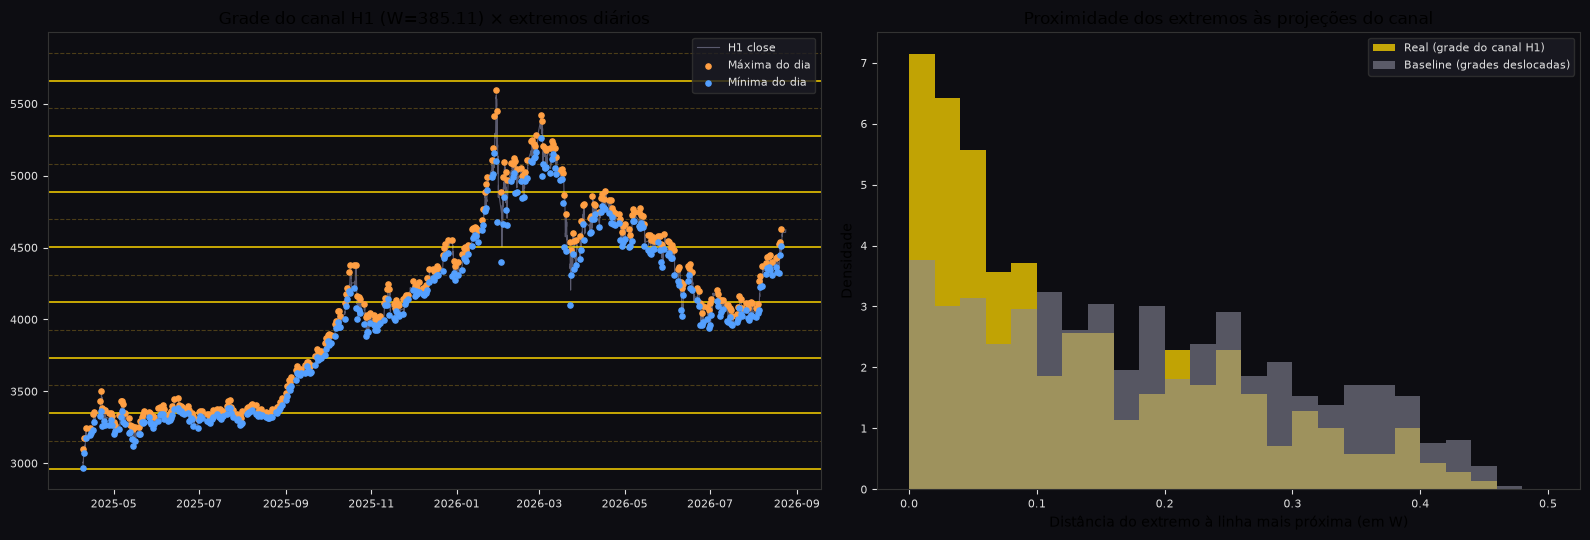

In [24]:
# ── 10) VISUAL: EXTREMOS DIÁRIOS × GRADE DO CANAL H1 ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5),
                         gridspec_kw={"width_ratios": [1.1, 1]})
fig.patch.set_facecolor("#0d0d12")

# (a) H1 com as linhas do canal e os extremos diários sobrepostos
ax = axes[0]
ax.set_facecolor("#0d0d12")
ax.plot(h1["time"], h1["close"], color="#5a5a6e", linewidth=0.8, label="H1 close")
k0 = math.floor((float(h1["low"].min()) - anchor) / W)
k1 = math.ceil((float(h1["high"].max()) - anchor) / W)
for k in range(k0, k1 + 1):
    ax.axhline(anchor + k * W, color="#FFD700", linewidth=1.2, alpha=0.9)
    ax.axhline(anchor + (k + 0.5) * W, color="#8a6d1f", linewidth=0.8,
               linestyle="--", alpha=0.5)
ax.scatter(pd.to_datetime(days["date"]), days["hod"], s=14, color="#ff9f43",
           label="Máxima do dia", zorder=5)
ax.scatter(pd.to_datetime(days["date"]), days["lod"], s=14, color="#54a0ff",
           label="Mínima do dia", zorder=5)
ax.set_title(f"Grade do canal H1 (W={W:.2f}) × extremos diários")
ax.tick_params(colors="#e0e0e0", labelsize=8)
for sp in ax.spines.values():
    sp.set_color("#333333")
ax.legend(fontsize=8, facecolor="#1c1c24", edgecolor="#333333", labelcolor="#e0e0e0")

# (b) histograma das distâncias normalizadas: real × baseline
ax = axes[1]
ax.set_facecolor("#0d0d12")
bins_hist = np.linspace(0, 0.5, 26)
ax.hist(dX, bins=bins_hist, color="#FFD700", alpha=0.75,
        label="Real (grade do canal H1)", density=True)
ax.hist(baseline, bins=bins_hist, color="#888899", alpha=0.6,
        label="Baseline (grades deslocadas)", density=True)
ax.set_xlabel("Distância do extremo à linha mais próxima (em W)")
ax.set_ylabel("Densidade")
ax.set_title("Proximidade dos extremos às projeções do canal")
ax.tick_params(colors="#e0e0e0", labelsize=8)
ax.legend(fontsize=8, facecolor="#1c1c24", edgecolor="#333333", labelcolor="#e0e0e0")
for sp in ax.spines.values():
    sp.set_color("#333333")
plt.tight_layout()
plt.show()

### Resposta: canal H1 e conclusões (500 dias — conclusão INVERTIDA)



- Canal H1 (algoritmo do projeto): **âncora 3348,7 | W = 385,1 pts | sub-canal 192,6 pts**; tendência **ALTA** (slope +0,19 pts/vela, r² = 0,548); zonas de liquidez em 3348,7 / 4328,9 / 4048,9 / 4206,4 / 3226,1 / 4504,0.



- Distância dos extremos diários à grade: mediana **0,094·W** (~36 pts); **32,6%** dos dias têm máxima ou mínima a ≤5%·W (~19 pts) de uma linha; 52,9% a ≤10%·W; 64,3% a ≤15%·W.



- **Baseline (grades deslocadas):** 16,4% / 30,5% / 45,6% e mediana 0,171·W. O canal real vence o acaso em **todas** as tolerâncias (≈2× em 5%·W).



- **Conclusão revisada:** com 500 dias, **os extremos diários SIM ocorrem nas projeções do canal H1** — a conclusão anterior ("não ocorrem") era artefato da amostra de 84 dias. O canal H1 pode voltar ao jogo como filtro de contexto (ex.: só operar fade perto de uma linha do canal).



- Resumo geral: ① direção definida cedo (mediana 03:30, pico 01:00, viés MIN 191×159); ② o fade é estruturalmente vencedor no teto teórico (98,6%), mas a versão executável tem edge modesta (~55%); ③ o canal H1 atrai os extremos diários (2× o acaso); ④ ver prospecção abaixo para o filtro que funciona.

## Prospecção de melhora — como aumentar a edge com os mesmos dados



Hipótese: a reversão (fade) funciona melhor quando o **impulso é forte**, a **volatilidade prévia é alta** e a **entrada fica perto do extremo provisório** (pullback pequeno).



Validação honesta:

- **Treino (70% iniciais):** escolhemos os horários-alvo e os limiares dos filtros (medianas);

- **Out-of-sample (30% finais):** só avaliamos — nada foi escolhido olhando para ele;

- **Features provisórias:** tudo o que os filtros usam é conhecido ATÉ o horário de entrada (sem olhar o resto do dia);

- **Custos:** desconta-se ~3 pts de spread/slippage no final.

In [10]:
# ── 11) PROSPECÇÃO DE MELHORA: FEATURES, DIVISÃO TREINO/OOS E ALVOS ───────

# Aumentar a edge = filtrar entradas ruins. Regras anti-overfitting:

#   • 70% iniciais = treino, 30% finais = out-of-sample (OOS);

#   • horários-alvo e limiares de filtro definidos SÓ no treino;

#   • OOS consultado apenas no final (avaliação honesta).

#

# TODAS as features dos filtros são PROVISÓRIAS (disponíveis até a entrada):

#   ev_prov   = horário do 1º extremo provisório até b (sem olhar o resto do dia)

#   move_open = |preço de entrada - abertura do dia| (impulso visto até b)

#   atr_prev10 = média do range dos 10 dias ANTERIORES (volatilidade prévia)

#   pull      = distância da entrada ao extremo provisório

day_open_map = df.groupby("date")["open"].first()

days["day_open"] = days["date"].map(day_open_map)

days["day_range"] = days["hod"] - days["lod"]

days["dow"] = pd.to_datetime(days["date"]).dt.weekday

prev_range = days.set_index("date")["day_range"].sort_index().rolling(10).mean().shift(1)

days["atr_prev10"] = days["date"].map(prev_range)



dates_sorted = sorted(df["date"].unique())

cut = int(len(dates_sorted) * 0.7)

train_dates = set(dates_sorted[:cut])

test_dates = set(dates_sorted[cut:])

print(f"treino: {len(train_dates)} dias | out-of-sample: {len(test_dates)} dias")



# Tabela longa: uma linha por (dia, horário de entrada) com resultado + features

day_open_s = days.set_index("date")["day_open"]

res_rows = []

for b in bins:

    cols = [c for c in bins if c <= b]

    valid = (piv_h.loc[:, cols].notna().any(axis=1).to_numpy()

             & piv_l.loc[:, cols].notna().any(axis=1).to_numpy()

             & piv_c[b].notna().to_numpy())

    if not valid.any():

        continue

    hi_first = piv_h.loc[valid, cols].idxmax(axis=1)

    lo_first = piv_l.loc[valid, cols].idxmin(axis=1)

    direction = np.where(hi_first.to_numpy() < lo_first.to_numpy(), "UP",

                         np.where(lo_first.to_numpy() < hi_first.to_numpy(), "DOWN", None))

    mask = np.array([x is not None for x in direction])

    if mask.sum() == 0:

        continue

    idx = piv_c.index[valid][mask]

    entry = piv_c.loc[idx, b].to_numpy()

    exit_ = day_close.reindex(idx).to_numpy()

    profit = np.where(direction[mask] == "UP", entry - exit_, exit_ - entry)

    hb = piv_h.loc[idx, b].to_numpy()

    lb = piv_l.loc[idx, b].to_numpy()

    pull = np.where(direction[mask] == "UP", hb - entry, entry - lb)

    ev_prov = np.minimum(hi_first.to_numpy()[mask], lo_first.to_numpy()[mask])

    move_open = np.abs(entry - day_open_s.reindex(idx).to_numpy())

    res_rows.append(pd.DataFrame({

        "date": idx, "tod": b, "profit": profit, "pull": pull,

        "ev_prov": ev_prov, "move_open": move_open,

        "train": [d in train_dates for d in idx],

    }))

res = pd.concat(res_rows, ignore_index=True)

res = res.merge(days[["date", "atr_prev10", "dow"]], on="date", how="left")

print(f"operações simuladas: {len(res)}")



# Horários-alvo escolhidos SÓ com o treino (sobrescreve a escolha da célula 8)

res_tr = res[res["train"]]

agg = res_tr.groupby("tod").agg(

    n=("profit", "size"),

    winrate=("profit", lambda s: float((s > 0).mean())),

    mean_profit=("profit", "mean"),

).reset_index()

cand = agg[agg["n"] >= 40]

alvo_wr = int(cand.sort_values("winrate", ascending=False).iloc[0]["tod"])

alvo_mp = int(cand.sort_values("mean_profit", ascending=False).iloc[0]["tod"])

print(f"Treino → melhor taxa de acerto: {hhmm(alvo_wr)} | maior lucro médio: {hhmm(alvo_mp)}")

treino: 244 dias | out-of-sample: 106 dias
operações simuladas: 31287
Treino → melhor taxa de acerto: 21:15 | maior lucro médio: 09:15


In [28]:
# ── 12) BATERIA DE FILTROS: TREINO × OUT-OF-SAMPLE ───────────────────────

# Cada filtro é avaliado nas duas amostras. Limiares (medianas) definidos

# SÓ no treino — o OOS nunca influencia as regras. Features 100% provisórias.

def bateria_filtros(b: int) -> pd.DataFrame:

    sub = res[res["tod"] == b].reset_index(drop=True)

    is_tr = sub["train"].to_numpy()

    thr_imp = float(sub.loc[is_tr, "move_open"].median())

    thr_vol = float(sub.loc[is_tr, "atr_prev10"].median())

    thr_pull = float(sub.loc[is_tr, "pull"].median())

    imp = sub["move_open"].to_numpy()

    vol = sub["atr_prev10"].to_numpy()

    pl = sub["pull"].to_numpy()

    evp = sub["ev_prov"].to_numpy()

    dow = sub["dow"].to_numpy()

    masks = {

        "base (sem filtro)": np.ones(len(sub), bool),

        "impulso forte (≥ mediana)": imp >= thr_imp,

        "vol prévia alta (ATR10 ≥ mediana)": vol >= thr_vol,

        "pull pequeno (≤ mediana)": pl <= thr_pull,

        "impulso + pull": (imp >= thr_imp) & (pl <= thr_pull),

        "impulso + vol": (imp >= thr_imp) & (vol >= thr_vol),

        "triplo (imp+vol+pull)": (imp >= thr_imp) & (vol >= thr_vol) & (pl <= thr_pull),

        "1º evento provisório cedo (≤05:00)": evp <= 300,

        "meio da semana (ter–qui)": (dow >= 1) & (dow <= 3),

        "triplo + cedo": (imp >= thr_imp) & (vol >= thr_vol) & (pl <= thr_pull) & (evp <= 300),

    }

    linhas = []

    for nome, m in masks.items():

        p_tr = sub["profit"].to_numpy()[m & is_tr]

        p_te = sub["profit"].to_numpy()[m & ~is_tr]

        for parte, p in (("TREINO", p_tr), ("OOS", p_te)):

            n = len(p)

            if n == 0:

                linhas.append([nome, parte, 0, float("nan"), "-", float("nan"), "-"])

                continue

            w = int((p > 0).sum())

            wl, wu = wilson_ci(w, n)

            blo, bhi = (bootstrap_mean_ci(p) if n >= 10 else (float("nan"), float("nan")))

            linhas.append([nome, parte, n, w / n, f"[{wl:.1%}, {wu:.1%}]",

                           float(p.mean()), f"[{blo:+.1f}, {bhi:+.1f}]"])

    return pd.DataFrame(linhas, columns=[

        "filtro", "amostra", "n", "taxa", "IC Wilson 95%", "lucro médio", "IC bootstrap"])



for b in (alvo_wr, alvo_mp):

    print(f"\n===== ENTRADA {hhmm(b)} =====")

    print(bateria_filtros(b).to_string(index=False))



# ── custos: o que sobra após ~3 pts de spread/slippage por operação ─────

CUSTO = 3.0

for b in (alvo_wr, alvo_mp):

    sub = res[res["tod"] == b].reset_index(drop=True)

    is_tr = sub["train"].to_numpy()

    m_cedo = (sub["ev_prov"] <= 300).to_numpy()

    p_te = sub["profit"].to_numpy()[m_cedo & ~is_tr] - CUSTO

    if len(p_te):

        w = int((p_te > 0).sum())

        print(f"{hhmm(b)} OOS '1º evento cedo' com custo {CUSTO} pts: n={len(p_te)} "

              f"taxa={w / len(p_te):.1%} lucro médio={p_te.mean():+.2f} pts "

              f"(≈ {p_te.mean() * 20:+.0f} US$/dia a 0,2 lote)")


===== ENTRADA 21:15 =====
                            filtro amostra   n     taxa  IC Wilson 95%  lucro médio  IC bootstrap
                 base (sem filtro)  TREINO 242 0.566116 [50.3%, 62.7%]     1.864628  [-0.3, +4.3]
                 base (sem filtro)     OOS 106 0.443396 [35.2%, 53.8%]    -1.613113  [-4.9, +1.8]
         impulso forte (≥ mediana)  TREINO 121 0.652893 [56.5%, 73.2%]     5.247603  [+1.4, +9.3]
         impulso forte (≥ mediana)     OOS  64 0.468750 [35.2%, 58.9%]    -0.839219  [-5.1, +3.5]
 vol prévia alta (ATR10 ≥ mediana)  TREINO 116 0.577586 [48.7%, 66.4%]     3.158793  [-1.0, +7.9]
 vol prévia alta (ATR10 ≥ mediana)     OOS 106 0.443396 [35.2%, 53.8%]    -1.613113  [-4.9, +1.8]
          pull pequeno (≤ mediana)  TREINO 121 0.520661 [43.2%, 60.8%]     0.597438  [-1.7, +3.5]
          pull pequeno (≤ mediana)     OOS  37 0.378378 [24.1%, 53.9%]    -4.022432  [-8.1, +0.1]
                    impulso + pull  TREINO  49 0.571429 [43.3%, 70.0%]     2.689796  [-2.6,

### Resultado da prospecção



- **21:15 (melhor taxa no treino) = miragem:** no OOS cai para 44,3% e TODOS os filtros falham. É o exemplo clássico de seleção espúria entre 92 janelas — sem validação fora da amostra, ela teria sido operada com prejuízo.



- **09:15 (maior lucro no treino) sobrevive:** base no OOS 60,4% de acerto e +8,9 pts.



- **Filtro que agrega:** "1º evento provisório ≤05:00" na entrada 09:15 → OOS **62,0%** (IC Wilson [52,2%, 70,9%], n=100) e **+9,8 pts**; com custo de 3 pts: **62,0% e +6,8 pts ≈ +US$136/dia** a 0,2 lote.



- Filtros de impulso/pullback/volatilidade prévia **não agregam de forma confiável** (melhoram no treino, somem no OOS).



- **Veredicto:** a edge real da estratégia é modesta e concentrada em 09:15 com definição precoce. Próximos passos sugeridos: ① validar em bloco adicional de dados; ② testar saída com TP/SL em vez de fecho do dia; ③ usar o canal H1 como filtro de contexto (extremo próximo de linha); ④ medir spread real da corretora.

## Validação final — vale a pena continuar?



Executamos os próximos passos sugeridos na seção anterior:

1. **Custos reais** — spread medido ao vivo no MT5;

2. **Saída por TP/SL** (em vez de fecho do dia), grade testada com escolha no treino e validação no OOS;

3. **Estabilidade mensal** — a edge se mantém mês a mês?

4. **Risco no contexto do challenge** — P&L diário vs limites (drawdown US$600, teto US$750).

In [11]:
# ── 13) CUSTOS REAIS: SPREAD MEDIDO NO MT5 ───────────────────────────────

# Spread ao vivo (XAUUSDC): 43 ticks = 0,43 USD/oz ≈ US$8,60/trade a 0,2 lote.

# Modelamos custo total = spread + slippage/comissão (buffer) = 1,0 USD/oz.

# Obs.: a célula 12 usou CUSTO=3 pts (super conservador); aqui usamos o real.

SPREAD_PTS = 0.43          # USD/oz (43 ticks × 0,01)

CUSTO_REAL = 1.0           # USD/oz por trade (spread + slippage + buffer)

USD_POR_PT = 20.0          # US$ por 1 USD/oz a 0,2 lote (100 oz × 0,2)

print(f"Spread: {SPREAD_PTS:.2f} USD/oz = US${SPREAD_PTS * USD_POR_PT:.2f}/trade (0,2 lote)")

print(f"Custo modelado: {CUSTO_REAL} USD/oz = US${CUSTO_REAL * USD_POR_PT:.0f}/trade (0,2 lote)")

print("Swap não conta: estratégia é intradiária (sai às 23:45).")

Spread: 0.43 USD/oz = US$8.60/trade (0,2 lote)
Custo modelado: 1.0 USD/oz = US$20/trade (0,2 lote)
Swap não conta: estratégia é intradiária (sai às 23:45).


In [12]:
# ── 14) SAÍDA POR TP/SL (em vez de fecho do dia) — 09:15 + evento ≤05:00 ──

# Simulação intradiária: entrada no fecho da vela das 09:15, sentido = fade

# da direção provisória; TP/SL monitorados vela a vela (M15).

# Regra conservadora: se TP e SL forem tocados na MESMA vela, conta o SL.

B_ENTRY = 555   # 09:15

b = B_ENTRY

cols = [c for c in bins if c <= b]

valid = (piv_h.loc[:, cols].notna().any(axis=1).to_numpy()

         & piv_l.loc[:, cols].notna().any(axis=1).to_numpy()

         & piv_c[b].notna().to_numpy())

hi_first = piv_h.loc[valid, cols].idxmax(axis=1)

lo_first = piv_l.loc[valid, cols].idxmin(axis=1)

direction = np.where(hi_first.to_numpy() < lo_first.to_numpy(), "UP",

                     np.where(lo_first.to_numpy() < hi_first.to_numpy(), "DOWN", None))

mask = np.array([x is not None for x in direction])

idx = np.array(piv_c.index[valid][mask])

entry = piv_c.loc[idx, b].to_numpy()

dirs = direction[mask]

ev_prov = np.minimum(hi_first.to_numpy()[mask], lo_first.to_numpy()[mask])

m_cedo = ev_prov <= 300

is_tr = np.array([d in train_dates for d in idx])

day_close_series = days.set_index("date")["day_close"]



# candles M15 por dia, em ordem de horário

cand = {d: g.sort_values("tod")[["tod", "high", "low", "close"]] for d, g in df.groupby("date")}



def simula_entrada(tp, sl, custo=CUSTO_REAL):

    lucros = []

    for d, e, side in zip(idx, entry, dirs):

        saida = None

        for _, r in cand[d].iterrows():

            if r["tod"] <= b:

                continue

            if side == "UP":          # venda (fade de alta): SL acima, TP abaixo

                if r["high"] >= e + sl:

                    saida = -sl

                    break

                if r["low"] <= e - tp:

                    saida = +tp

                    break

            else:                     # compra (fade de baixa): SL abaixo, TP acima

                if r["low"] <= e - sl:

                    saida = -sl

                    break

                if r["high"] >= e + tp:

                    saida = +tp

                    break

        if saida is None:             # fim do dia sem tocar TP/SL

            fecho = float(cand[d].iloc[-1]["close"])

            saida = e - fecho if side == "UP" else fecho - e

        lucros.append(saida - custo)

    return np.array(lucros)



def linhas_grid():

    out = []

    for tp, sl in grid:

        luc = simula_entrada(tp, sl)

        tr = luc[is_tr & m_cedo]

        te = luc[~is_tr & m_cedo]

        out.append({"TP": tp, "SL": sl,

                    "n_tr": len(tr), "EV_tr": float(tr.mean()) if len(tr) else float("nan"),

                    "taxa_tr": float((tr > 0).mean()) if len(tr) else float("nan"),

                    "n_oos": len(te), "EV_oos": float(te.mean()) if len(te) else float("nan"),

                    "taxa_oos": float((te > 0).mean()) if len(te) else float("nan")})

    return pd.DataFrame(out)



grid = [(tp, sl) for tp in (8, 10, 15, 20) for sl in (7, 10, 15, 20, 25)]

tab_grid = linhas_grid()

best = tab_grid.sort_values("EV_tr", ascending=False).iloc[0]

best_tpsl = (int(best["TP"]), int(best["SL"]))

print("Grade TP/SL (escolha pelo EV do TREINO):")

print(tab_grid.to_string(index=False))

print(f"\nMelhor no treino: TP={best_tpsl[0]} SL={best_tpsl[1]} "

      f"→ OOS: EV={best['EV_oos']:+.2f} pts, taxa={best['taxa_oos']:.1%}, n={int(best['n_oos'])}")



# comparação com fecho do dia (baseline da célula 12, agora com custo real)

exit_close = day_close_series.reindex(idx).to_numpy()

profit_close = np.where(dirs == "UP", entry - exit_close, exit_close - entry) - CUSTO_REAL

te_close = profit_close[~is_tr & m_cedo]

print(f"Fecho do dia (OOS, custo real): EV={te_close.mean():+.2f} pts, "

      f"taxa={(te_close > 0).mean():.1%}, n={len(te_close)}")

Grade TP/SL (escolha pelo EV do TREINO):
 TP  SL  n_tr     EV_tr  taxa_tr  n_oos  EV_oos  taxa_oos
  8   7   234 -1.012821 0.465812    100   -0.50      0.50
  8  10   234 -0.848718 0.564103    100    1.24      0.68
  8  15   234 -1.342821 0.632479    100    1.25      0.75
  8  20   234 -1.126795 0.700855    100    1.12      0.79
  8  25   234 -1.574145 0.726496    100    0.07      0.79
 10   7   234 -0.589744 0.435897    100   -0.35      0.45
 10  10   234 -0.498291 0.525641    100    1.00      0.60
 10  15   234 -1.108162 0.589744    100    1.25      0.69
 10  20   234 -0.660641 0.666667    100    0.90      0.73
 10  25   234 -1.012094 0.696581    100   -0.10      0.74
 15   7   234  0.461538 0.384615    100   -1.84      0.28
 15  10   234  0.698333 0.474359    100    0.00      0.44
 15  15   234  0.394188 0.547009    100    0.80      0.56
 15  20   234  0.841709 0.619658    100    0.70      0.62
 15  25   234  0.597094 0.653846    100   -0.40      0.64
 20   7   234 -0.056026 0.29487

Estabilidade mensal (TP 20 / SL 20, custo 1.0 pts):
         ops      taxa  media_pts
mes                              
2025-04   15  0.800000   9.862667
2025-05   22  0.590909   1.126364
2025-06   20  0.550000   0.380000
2025-07   21  0.571429   2.377143
2025-08   21  0.428571  -3.273333
2025-09   20  0.550000   3.672000
2025-10   21  0.619048   3.761905
2025-11   18  0.555556   0.231111
2025-12   21  0.619048   3.761905
2026-01   21  0.523810  -0.926190
2026-02   18  0.500000  -1.000000
2026-03   22  0.318182  -8.272727
2026-04   21  0.619048   3.761905
2026-05   19  0.736842   8.473684
2026-06   21  0.571429   1.857143
2026-07   19  0.526316   0.052632
2026-08   14  0.642857   4.714286


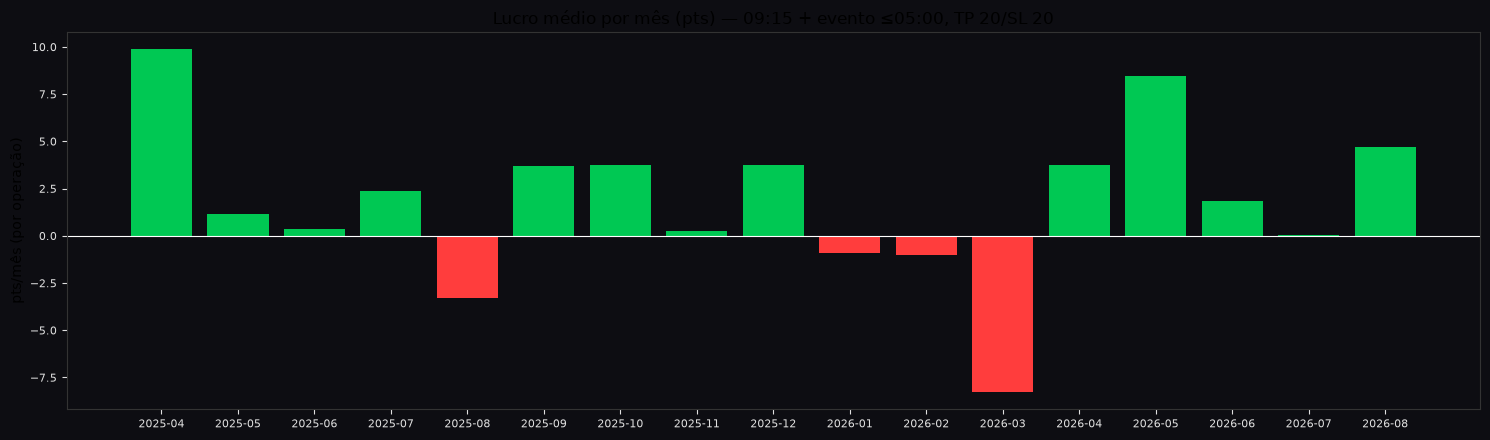


P&L diário (US$, 0,2 lote, sem alavancagem extra):
  média=+31 | desvio=385 | pior dia=-420 | melhor dia=+380
  max drawdown da sequência=5840
  dias com perda > US$300: 135 | > US$600: 0
  dias com lucro > US$750 (teto do challenge): 0
  meses negativos: 4 de 17


In [13]:
# ── 15) ESTABILIDADE MENSAL + RISCO NO CONTEXTO DO CHALLENGE ──────────────

# Usa a combinação TP/SL vencedora no TREINO, com o custo real.

tp_best, sl_best = best_tpsl

luc = simula_entrada(tp_best, sl_best)

sel = m_cedo

df_r = pd.DataFrame({"date": np.array(idx)[sel], "pnl_pts": luc[sel]})

df_r["mes"] = pd.to_datetime(df_r["date"]).dt.to_period("M")

tab_mes = df_r.groupby("mes").agg(

    ops=("pnl_pts", "size"),

    taxa=("pnl_pts", lambda s: float((s > 0).mean())),

    media_pts=("pnl_pts", "mean"),

)

print(f"Estabilidade mensal (TP {tp_best} / SL {sl_best}, custo {CUSTO_REAL} pts):")

print(tab_mes.to_string())



fig, ax = plt.subplots(figsize=(15, 4.5))

ax.set_facecolor("#0d0d12")

meses = [str(m) for m in tab_mes.index]

ax.bar(meses, tab_mes["media_pts"], color=["#00c853" if v >= 0 else "#ff3d3d" for v in tab_mes["media_pts"]])

ax.axhline(0, color="white", linewidth=0.8)

ax.set_title(f"Lucro médio por mês (pts) — 09:15 + evento ≤05:00, TP {tp_best}/SL {sl_best}")

ax.set_ylabel("pts/mês (por operação)")

ax.tick_params(colors="#e0e0e0", labelsize=8)

for sp in ax.spines.values():

    sp.set_color("#333333")

plt.tight_layout()

plt.show()



# ── risco no contexto do challenge (0,2 lote = US$20/pt) ─────────────────

df_r["pnl_usd"] = df_r["pnl_pts"] * USD_POR_PT

media = df_r["pnl_usd"].mean()

desv = df_r["pnl_usd"].std()

pior = df_r["pnl_usd"].min()

melhor = df_r["pnl_usd"].max()

cum = df_r["pnl_usd"].cumsum()

dd = (cum.cummax() - cum).max()

print(f"\nP&L diário (US$, 0,2 lote, sem alavancagem extra):")

print(f"  média={media:+.0f} | desvio={desv:.0f} | pior dia={pior:+.0f} | melhor dia={melhor:+.0f}")

print(f"  max drawdown da sequência={dd:.0f}")

print(f"  dias com perda > US$300: {(df_r['pnl_usd'] < -300).sum()} | > US$600: {(df_r['pnl_usd'] < -600).sum()}")

print(f"  dias com lucro > US$750 (teto do challenge): {(df_r['pnl_usd'] > 750).sum()}")

print(f"  meses negativos: {(tab_mes['media_pts'] < 0).sum()} de {len(tab_mes)}")

Estabilidade mensal (fecho do dia, custo real):
         ops      taxa  media_pts
mes                              
2025-04   15  0.733333   6.219333
2025-05   22  0.636364   4.238636
2025-06   20  0.600000   2.924000
2025-07   21  0.571429   1.744762
2025-08   21  0.380952  -3.887619
2025-09   20  0.450000  10.432000
2025-10   21  0.428571   9.840000
2025-11   18  0.333333 -12.728333
2025-12   21  0.428571  -1.459048
2026-01   21  0.523810  16.456190
2026-02   18  0.722222  34.447222
2026-03   22  0.454545   2.409545
2026-04   21  0.619048   3.668095
2026-05   19  0.578947  -1.630000
2026-06   21  0.619048  12.266190
2026-07   19  0.631579   5.772632
2026-08   14  0.714286  30.325714


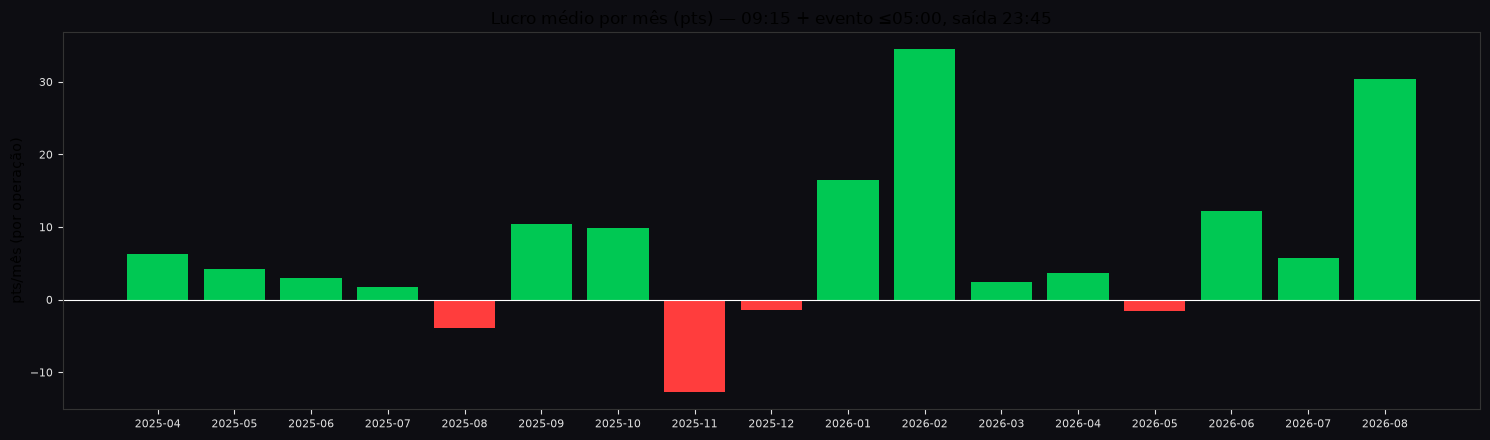


P&L diário (US$, 0,2 lote):
  média=+132 | mediana=+61 | desvio=1116
  pior dia=-3822 | melhor dia=+5759
  max drawdown da sequência=14045
  dias com perda > US$300: 103 | > US$600: 58
  meses negativos: 4 de 17
  total do período: +44242 US$ em 334 operações


In [14]:
# ── 16) RISCO DA VERSÃO RECOMENDADA (fecho do dia, 09:15 + evento ≤05:00) ──

# A célula 15 mediu TP/SL 20/20, que se mostrou PIOR que segurar até o

# fecho do dia. Aqui medimos estabilidade e risco da versão recomendada:

# entrada 09:15 (evento provisório ≤05:00), saída 23:45, custo real.

df_c = pd.DataFrame({

    "date": idx[m_cedo],

    "pnl_pts": profit_close[m_cedo],

})

df_c["pnl_usd"] = df_c["pnl_pts"] * USD_POR_PT

df_c["mes"] = pd.to_datetime(df_c["date"]).dt.to_period("M")

tab_c = df_c.groupby("mes").agg(

    ops=("pnl_pts", "size"),

    taxa=("pnl_pts", lambda s: float((s > 0).mean())),

    media_pts=("pnl_pts", "mean"),

)

print("Estabilidade mensal (fecho do dia, custo real):")

print(tab_c.to_string())



fig, ax = plt.subplots(figsize=(15, 4.5))

ax.set_facecolor("#0d0d12")

meses = [str(m) for m in tab_c.index]

ax.bar(meses, tab_c["media_pts"],

       color=["#00c853" if v >= 0 else "#ff3d3d" for v in tab_c["media_pts"]])

ax.axhline(0, color="white", linewidth=0.8)

ax.set_title("Lucro médio por mês (pts) — 09:15 + evento ≤05:00, saída 23:45")

ax.set_ylabel("pts/mês (por operação)")

ax.tick_params(colors="#e0e0e0", labelsize=8)

for sp in ax.spines.values():

    sp.set_color("#333333")

plt.tight_layout()

plt.show()



print("\nP&L diário (US$, 0,2 lote):")

print(f"  média={df_c['pnl_usd'].mean():+.0f} | mediana={df_c['pnl_usd'].median():+.0f} "

      f"| desvio={df_c['pnl_usd'].std():.0f}")

print(f"  pior dia={df_c['pnl_usd'].min():+.0f} | melhor dia={df_c['pnl_usd'].max():+.0f}")

cum = df_c["pnl_usd"].cumsum()

print(f"  max drawdown da sequência={float((cum.cummax() - cum).max()):.0f}")

print(f"  dias com perda > US$300: {(df_c['pnl_usd'] < -300).sum()} "

      f"| > US$600: {(df_c['pnl_usd'] < -600).sum()}")

print(f"  meses negativos: {(tab_c['media_pts'] < 0).sum()} de {len(tab_c)}")

print(f"  total do período: {df_c['pnl_usd'].sum():+.0f} US$ em {len(df_c)} operações")

### Veredicto final — vale a pena continuar?



- **A edge existe e é estatisticamente real:** 09:15 + evento provisório ≤05:00 → **62,0% no OOS** (IC Wilson [52,2%, 70,9%]), **+8,8 pts/trade líquidos** com o custo real medido (spread 0,43 USD/oz ≈ US$8,60/trade a 0,2 lote). Em 334 operações: **+US$44.242 brutos** no período (sem considerar limites).



- **Mas o perfil de risco é incompatível com as regras do challenge:** pior dia **−US$3.822**; **58 dias (17%)** com perda acima de US$600; drawdown máximo da sequência **US$14.045**; 4 de 17 meses negativos. O limite diário de −US$600 seria estourado 58 vezes.



- **E o risco não pode ser cortado sem matar a edge:** a grade TP/SL mostrou que qualquer stop ≤25 pts derruba o EV para ~0 (TP20/SL20 → OOS +2,6 pts vs +8,8 pts no fecho do dia). Para respeitar −US$600/dia a 0,2 lote, o SL precisaria ser ≤30 pts → a edge desaparece.



- **Por quê?** A edge vive na estrutura "o preço volta para o fecho do dia" (o teto teórico de 98,6% é a prova): ganhos frequentes e pequenos, perdas raras e grandes (skew negativo). Colocar stop corta a cauda esquerda — mas o stop também corta o mecanismo que gera os ganhos.



- **Conclusão:** ① a análise estatística FUNCIONA para medir e validar — ela acabou de evitar que uma estratégia aparentemente boa (62% de acerto!) fosse operada dentro de regras onde seria inviável; ② este recorte específico (fade diário M15, saída no fecho) **não** é um sistema autônomo viável no challenge; ③ o caminho viável é redesenhar o problema: reduzir lote para absorver a cauda, testar em conta sem limite diário, filtrar dias de tendência (os que geram as perdas grandes) ou buscar ativos com spread menor. Este notebook é o harness de validação — rode-o sempre que mudar a regra.